In [1]:
###############################################################################
#Package Imports & Environment Setup
###############################################################################
import os 


import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import lal
import lal as _lal
import numpy as np
import matplotlib.pyplot as plt

# PyCBC core
import pycbc
import pycbc.psd
import pycbc.noise
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.catalog import Merger
from pycbc.waveform import get_td_waveform, get_fd_waveform
from pycbc.waveform import get_fd_waveform_modes, get_td_waveform_modes
from pycbc.waveform.waveform_modes import get_imrphenomxh_modes
from pycbc.filter.matchedfilter import match, optimized_match
from pycbc.filter import highpass_fir, lowpass_fir
from pycbc.psd import welch, interpolate
from pycbc.types import Array
from pycbc.filter import matchedfilter
from pycbc.waveform.waveform import get_waveform_filter_norm
from pycbc import dq
from pycbc.results import ifo_color
import h5py
from pycbc.types import FrequencySeries, TimeSeries
from pycbc.psd.estimate import interpolate
import pycbc.scheme as _scheme
from pycbc.scheme import schemed, cpuonly
from pycbc.opt import LimitedSizeDict
from pycbc.waveform import td_approximants, fd_approximants
from pycbc.filter import sigmasq
BACKEND_PREFIX="pycbc.types.array_"


# PyCBC filtering
from pycbc.filter.matchedfilter import match, optimized_match
from pycbc.filter import highpass_fir, lowpass_fir, matchedfilter, sigmasq
from pycbc.psd import welch, interpolate

# Scientific computing
from scipy.interpolate import interp1d
from scipy.integrate import quad, simps, quadrature, romberg
import scipy.stats as stats
from scipy.stats import skew, kurtosis

# Machine learning
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns


from numpy import float32, float64, complex64, complex128, ones
from numpy.linalg import norm
import pandas as pd





os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'

os.environ['TF_DETERMINISTIC_OPS'] = '1'
# Matplotlib configuration
plt.rcParams['figure.figsize'] = (10, 6)

2025-04-09 23:33:25.424228: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Analytic waveforms

## PSD and parameters

First, we set up some information about the detector.

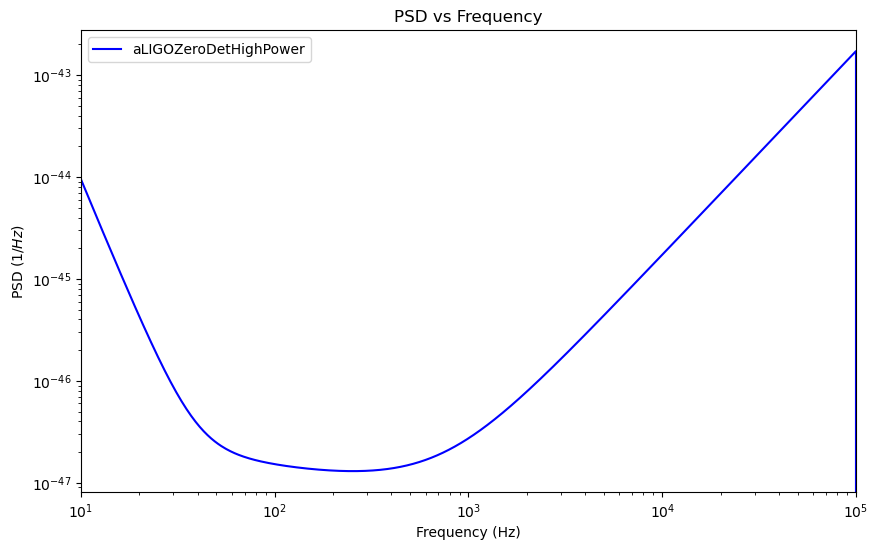

['IMRPhenomXHM']

In [2]:
inc_avg_factor = 2./np.sqrt(5)
sky_pol_avg_factor = 1./np.sqrt(5)
avg_factor = inc_avg_factor * sky_pol_avg_factor

flow, fmax = 10, 1e5
deltaf = 1
flen = int((fmax - flow) / deltaf)

psd_LIGO = psd_LIGO = pycbc.psd.analytical.aLIGOZeroDetHighPower(flen, deltaf, flow)
psd = psd_LIGO

psd_unity = pycbc.psd.analytical.flat_unity(flen, deltaf, flow)


plt.figure(figsize=(10, 6))
plt.loglog(psd, label='aLIGOZeroDetHighPower', color='blue')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD ($1/Hz$)')
plt.title('PSD vs Frequency')
plt.legend()
plt.xlim(flow, fmax)
plt.savefig('PSD.png')
plt.show()

pycbc.waveform.waveform_modes.fd_waveform_mode_approximants()
# print(fd_approximants())


and now the events

In [3]:
# Load the dataset
df_bbhs_named = pd.read_csv("../data/bbh_events.csv")

df_bbhs_named.head(1331)

# event_name = df_bbhs_named.iloc[165]["id"]  # 165th entry (0-based index)
# print(event_name)


,id,mass_1_source,mass_2_source,chi_eff,redshift
0,GW150914-v3,35.6,30.6,-0.01,0.09
1,GW151012-v3,23.2,13.6,0.05,0.21
2,GW151226-v2,13.7,7.7,0.18,0.09
3,GW170104-v2,30.8,20.0,-0.04,0.20
4,GW170608-v3,11.0,7.6,0.03,0.07
...,...,...,...,...,...
116,GW200306_093714-v1,28.3,14.8,0.32,0.38
117,GW200308_173609-v1,60.0,24.0,0.16,1.04
118,GW200311_115853-v1,34.2,27.7,-0.02,0.23
119,GW200316_215756-v1,13.1,7.8,0.13,0.22


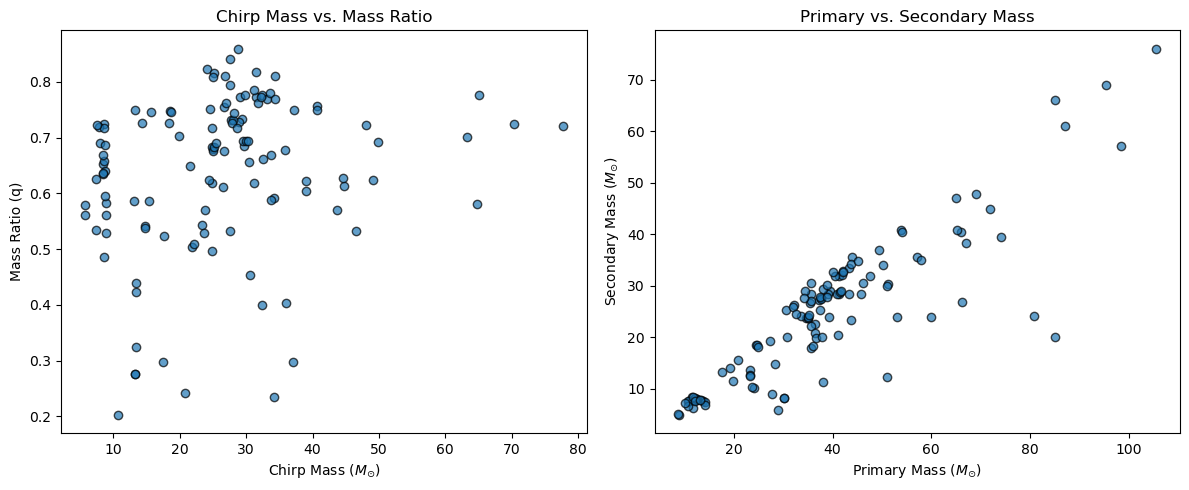

In [4]:
# Compute Chirp Mass
df_bbhs_named["chirp_mass"] = (df_bbhs_named["mass_1_source"] * df_bbhs_named["mass_2_source"]) ** (3 / 5) / \
                              (df_bbhs_named["mass_1_source"] + df_bbhs_named["mass_2_source"]) ** (1 / 5)

# Compute Mass Ratio (q = m2 / m1)
df_bbhs_named["mass_ratio"] = df_bbhs_named["mass_2_source"] / df_bbhs_named["mass_1_source"]

# Set up subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter plot: Chirp Mass vs. Mass Ratio
axes[0].scatter(df_bbhs_named["chirp_mass"], df_bbhs_named["mass_ratio"], alpha=0.7, edgecolor="black")
axes[0].set_xlabel(r"Chirp Mass ($M_{\odot}$)")
axes[0].set_ylabel("Mass Ratio (q)")
axes[0].set_title("Chirp Mass vs. Mass Ratio")

# Scatter plot: Primary Mass vs. Secondary Mass
axes[1].scatter(df_bbhs_named["mass_1_source"], df_bbhs_named["mass_2_source"], alpha=0.7, edgecolor="black")
axes[1].set_xlabel(r"Primary Mass ($M_{\odot}$)")
axes[1].set_ylabel(r"Secondary Mass ($M_{\odot}$)")
axes[1].set_title("Primary vs. Secondary Mass")

# Adjust layout and show plots
plt.tight_layout()
plt.savefig('Ligo_Data.png')
plt.show()




In [5]:
# Define the number of augmented samples per original event
num_augmentations = 10

# Create a copy of the original dataframe to avoid modifying it
df_augmented_bbhs = df_bbhs_named.copy()

# List to store new augmented rows
augmented_data = []

# Iterate over each row in the original dataset
for _, row in df_bbhs_named.iterrows():
    for _ in range(num_augmentations):
        # Generate perturbations (Gaussian noise with std of 3% to 5% of the original value)
        perturbation_factor = np.random.uniform(0.03, 0.05)  # 3% to 5% variation
        
        # Perturb masses (ensuring m1 > m2)
        new_mass_1 = np.random.normal(row["mass_1_source"], perturbation_factor * row["mass_1_source"])
        new_mass_2 = np.random.normal(row["mass_2_source"], perturbation_factor * row["mass_2_source"])

        # Ensure primary mass is always greater than secondary mass
        if new_mass_1 < new_mass_2:
            new_mass_1, new_mass_2 = new_mass_2, new_mass_1

        # Perturb effective spin
        new_chi_eff = np.random.normal(row["chi_eff"], perturbation_factor * abs(row["chi_eff"]) + 0.01)

        # Ensure chi_eff stays within the valid range (-1 to 1)
        new_chi_eff = np.clip(new_chi_eff, -1, 1)

        # Create a new row with modified values
        new_event = row.copy()
        new_event["mass_1_source"] = new_mass_1
        new_event["mass_2_source"] = new_mass_2
        new_event["chi_eff"] = new_chi_eff
        
        # Append to list
        augmented_data.append(new_event)

# Convert augmented data list to DataFrame
df_augmented_bbhs = pd.concat([df_bbhs_named, pd.DataFrame(augmented_data)], ignore_index=True)

# Display confirmation message
print(f"✅ Data augmentation complete! The dataset now contains {len(df_augmented_bbhs)} events.")


✅ Data augmentation complete! The dataset now contains 1331 events.


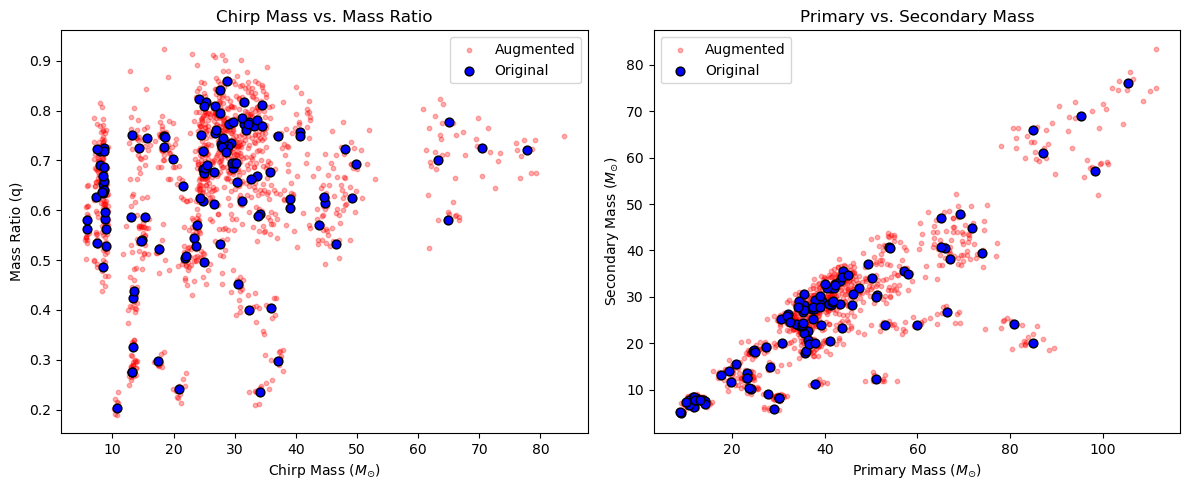

In [6]:
# Compute Chirp Mass and Mass Ratio for the full dataset
df_augmented_bbhs["chirp_mass"] = (df_augmented_bbhs["mass_1_source"] * df_augmented_bbhs["mass_2_source"]) ** (3 / 5) / \
                                  (df_augmented_bbhs["mass_1_source"] + df_augmented_bbhs["mass_2_source"]) ** (1 / 5)
df_augmented_bbhs["mass_ratio"] = df_augmented_bbhs["mass_2_source"] / df_augmented_bbhs["mass_1_source"]

# Separate original and augmented datasets for plotting
df_augmented_only = df_augmented_bbhs.iloc[len(df_bbhs_named):]  # Select only the newly generated data

# Set up subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter plot: Chirp Mass vs. Mass Ratio (Original vs. Augmented)
axes[0].scatter(df_augmented_only["chirp_mass"], df_augmented_only["mass_ratio"], 
                alpha=0.3, s=10, label="Augmented", color="red")  # Smaller & faded
axes[0].scatter(df_bbhs_named["chirp_mass"], df_bbhs_named["mass_ratio"], 
                alpha=1.0, s=40, label="Original", color="blue", edgecolors="black")  # Bold original
axes[0].set_xlabel(r"Chirp Mass ($M_{\odot}$)")
axes[0].set_ylabel("Mass Ratio (q)")
axes[0].set_title("Chirp Mass vs. Mass Ratio")
axes[0].legend()

# Scatter plot: Primary Mass vs. Secondary Mass (Original vs. Augmented)
axes[1].scatter(df_augmented_only["mass_1_source"], df_augmented_only["mass_2_source"], 
                alpha=0.3, s=10, label="Augmented", color="red")  # Smaller & faded
axes[1].scatter(df_bbhs_named["mass_1_source"], df_bbhs_named["mass_2_source"], 
                alpha=1.0, s=40, label="Original", color="blue", edgecolors="black")  # Bold original
axes[1].set_xlabel(r"Primary Mass ($M_{\odot}$)")
axes[1].set_ylabel(r"Secondary Mass ($M_{\odot}$)")
axes[1].set_title("Primary vs. Secondary Mass")
axes[1].legend()

# Adjust layout and show plots
plt.tight_layout()
plt.savefig('Augmented_Data.png')
plt.show()



In [7]:
# Extract event IDs as a simple list of indices
event_ids = df_augmented_bbhs.index.tolist()  # Retains natural index

# Extract relevant parameters as lists
mass1 = df_augmented_bbhs["mass_1_source"].tolist()
mass2 = df_augmented_bbhs["mass_2_source"].tolist()
chi_eff = df_augmented_bbhs["chi_eff"].tolist()
z_src = df_augmented_bbhs["redshift"].tolist()

# Generate chi_r randomly within a reasonable range for non-precessing BHs (-1 to 1)
np.random.seed(42)  # For reproducibility
chi_r = np.random.uniform(0.1, 0.9, len(event_ids)).tolist()

# Generate random inclination angles between 0 and π (for uniform distribution in solid angle)
inc =np.random.uniform(0, 0, len(event_ids)).tolist()


# Initialize dictionaries for parameters
M = {}
q = {}
eta = {}
spin_primary = {}
spin_secondary = {}
params_source = {}
params_source_22 = {}
params_source_21 = {}


# Generate parameters for each event
for event, m1, m2, chi, z, chi_r_val, inc_val in zip(event_ids, mass1, mass2, chi_eff, z_src, chi_r, inc):
    M[event] = m1 + m2
    q[event] = m2 / m1
    eps = 1e-6  # Small constant to prevent division by zero
    spin_primary[event] = chi * (m1 + m2) / (m1 + m2 * chi_r_val + eps)
    spin_secondary[event] = chi_r_val * spin_primary[event]
    eta[event] = (m1 * m2) / (M[event] ** 2)

    # Common parameters dictionary
    common_params = {
        'approximant': "IMRPhenomXHM",
        'mass1': m1 * (1 + z),
        'mass2': m2 * (1 + z),
        'spin1z': spin_primary[event],
        'spin2z': spin_secondary[event],
        'redshift': z,
        'inclination': 0,
        'long_asc_nodes': 0,
        'f_lower': 10,
        'delta_f': deltaf,  # Make sure deltaf is defined
        'delta_t': 1.0 / 4096,
    }

    # Store the common parameters in different mode configurations
    params_source[event] = common_params.copy()
    params_source_22[event] = {**common_params, 'mode_array': [(2, 2)]}
    params_source_21[event] = {**common_params, 'mode_array': [(2, 1)]}


In [8]:
print("Max spin_primary:", max(spin_primary.values()))
print("Min spin_primary:", min(spin_primary.values()))
print("Max spin_secondary:", max(spin_secondary.values()))
print("Min spin_secondary:", min(spin_secondary.values()))


print("Min chi_r:", min(chi_r))
print("Max chi_r:", max(chi_r))



invalid_spin_events = [event for event in event_ids if abs(spin_primary[event]) > 1 or abs(spin_secondary[event]) > 1]

# Print the invalid event labels
print("Events with unphysical spins (outside [-1,1]):")
print(invalid_spin_events)

Max spin_primary: 0.8175945157250798
Min spin_primary: -0.4395670881684813
Max spin_secondary: 0.5940968662432394
Min spin_secondary: -0.22566724779792166
Min chi_r: 0.1037056184036823
Max chi_r: 0.8997741386289045
Events with unphysical spins (outside [-1,1]):
[]


## Waveforms

In [9]:
# --- Waveform Generation in the Frequency Domain ---

# Initialize empty dictionaries to store results
freqs = {}      # Sample frequencies
hpf = {}        # Frequency domain waveform (plus)
hpf_22 = {}     # (2,2) mode
hpf_21 = {}     # (2,1) mode
phase = {}
phase_22 = {}
phase_21 = {}

# Upper and lower frequency cut-offs
f_lo = {}
f_hi = {}

# Indices of the upper and lower frequency cut-offs
id_lo = {}
id_hi = {}

# Generate waveforms for each event using event IDs
for event in event_ids:
    try:
        # Generate full waveform
        params = params_source[event]
        hpf[event], _ = get_fd_waveform(**params)
        freqs[event] = hpf[event].sample_frequencies
        phase[event] = np.angle(hpf[event])

        # Generate (2,2) mode waveform
        params_22 = params_source_22[event]
        hpf_22[event], _ = get_fd_waveform(**params_22)
        phase_22[event] = np.angle(hpf_22[event])

        # Generate (2,1) mode waveform
        params_21 = params_source_21[event]
        hpf_21[event], _ = get_fd_waveform(**params_21)
        phase_21[event] = np.angle(hpf_21[event])

        # Find non-zero frequency indices
        hpf_array = hpf[event].numpy()  # Convert to NumPy array if needed
        nonzero_indices = np.nonzero(hpf_array)[0]  # Get nonzero indices

        if len(nonzero_indices) > 0:  # Ensure we have nonzero values
            id_lo[event] = nonzero_indices[0]
            id_hi[event] = nonzero_indices[-1]
            f_lo[event] = freqs[event][id_lo[event]]
            f_hi[event] = freqs[event][id_hi[event]]
        else:
            id_lo[event] = None
            id_hi[event] = None
            f_lo[event] = None
            f_hi[event] = None

    except Exception as e:
        print(f"⚠️ Warning: Failed to generate waveform for event {event}. Error: {e}")


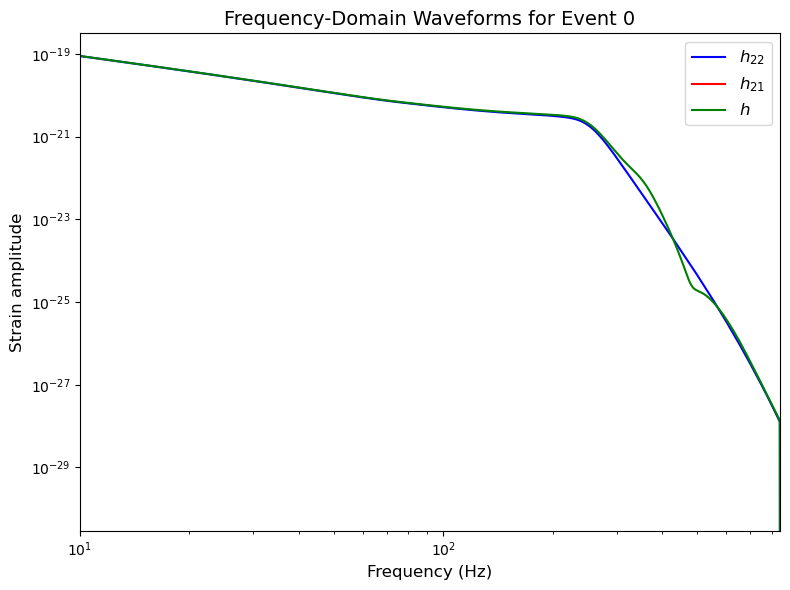

In [10]:

# Choose an event to plot (use a unique event ID)
event_id = event_ids[0]  # Change this to any event from your dataset

# Ensure the event ID exists in the waveform dictionaries
if event_id in freqs and event_id in hpf and event_id in hpf_22 and event_id in hpf_21:
    # Extract frequency-domain waveforms for the chosen event
    f_values = freqs[event_id]          # Frequency array
    h_22 = np.abs(hpf_22[event_id])     # (2,2) mode
    h_21 = np.abs(hpf_21[event_id])     # (2,1) mode
    h_total = np.abs(hpf[event_id])     # Full waveform (plus polarization)

    # Create the plot
    fig, ax = plt.subplots(figsize=(8,6))
    ax.plot(f_values, h_22, color='blue', label='$h_{22}$')
    ax.plot(f_values, h_21, color='red', label='$h_{21}$')
    ax.plot(f_values, h_total, color='green', label='$h$')

    # Set labels and scales
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Strain amplitude', fontsize=12)
    ax.set_title(f"Frequency-Domain Waveforms for Event {event_id}", fontsize=14)
    ax.set_xscale('log')
    ax.set_yscale('log')

    # Check if f_lo and f_hi exist before setting limits
    if event_id in f_lo and event_id in f_hi and f_lo[event_id] is not None and f_hi[event_id] is not None:
        ax.set_xlim([f_lo[event_id], f_hi[event_id]])
    
    ax.legend(fontsize=12)
    plt.tight_layout()
    plt.show()
    
else:
    print(f"⚠️ Warning: Event {event_id} not found in waveform data. Check if the waveform was generated properly.")


# GR modification and Noise Injections 

In this section, we introduce modification to GR by slightly extending the phase of the waveform. We also inject
some Gaussian noise to create some "realistic" data for the future computations.

### Phase variations

In [19]:
# event_id = 285  # The event number to investigate

# # Ensure the event exists in the dataset
# if event_id in event_ids:
#     print(f"🔍 **Event {event_id} Parameters:**")

#     # Extract masses and mass ratio
#     mass1_event = params_source[event_id]['mass1']
#     mass2_event = params_source[event_id]['mass2']
#     q_event = mass2_event / mass1_event

#     # Extract spin parameters
#     spin1z_event = params_source[event_id]['spin1z']
#     spin2z_event = params_source[event_id]['spin2z']

#     # Extract inclination
#     inclination_event = params_source[event_id]['inclination']

#     # Extract redshift
#     redshift_event = params_source[event_id]['redshift']

#     # Print the values
#     print(f"  🔹 Mass 1: {mass1_event:.4f} M_sun")
#     print(f"  🔹 Mass 2: {mass2_event:.4f} M_sun")
#     print(f"  🔹 Mass Ratio (q): {q_event:.4f}")
#     print(f"  🔹 Spin 1z: {spin1z_event:.4f}")
#     print(f"  🔹 Spin 2z: {spin2z_event:.4f}")
#     print(f"  🔹 Inclination Angle: {inclination_event:.4f} radians")
#     print(f"  🔹 Redshift: {redshift_event:.4f}")

#     # Check the waveform model being used
#     if event_id in params_source_22:
#         approximant = params_source_22[event_id]['approximant']
#         print(f"  🔹 Waveform Approximant: {approximant}")

# else:
#     print(f"⚠️ Warning: Event {event_id} not found in dataset.")


In [11]:
def modify_gr_to_bgr(event_id, beta=1):
    """Applies a Gaussian phase shift to create a BGR waveform."""
    
    # Ensure the event ID exists in required dictionaries
    if event_id not in freqs or event_id not in hpf or event_id not in hpf_22:
        print(f"⚠️ Warning: Event {event_id} is missing from GR waveform data. Skipping modification.")
        return None, None  # Return None to indicate failure

    try:
        # Get frequency array and GR waveforms
        freq_array = freqs[event_id]  
        hp_gr_full = hpf[event_id]  
        hp22_gr_full = hpf_22[event_id]  

        # Ensure freq_array is valid
        if freq_array is None or len(freq_array) == 0:
            print(f"⚠️ Warning: Empty frequency array for Event {event_id}. Skipping modification.")
            return None, None

        # Build Gaussian phase shift
        gauss_shift = beta * np.exp(-((freq_array - 50) ** 2) / 100.0)

        # Apply phase shift correctly using complex exponential
        h_bgr_full = hp_gr_full +(1j*hp22_gr_full* gauss_shift)
        h22_bgr_full = hp22_gr_full +(1j*hp22_gr_full* gauss_shift)

        return h_bgr_full, h22_bgr_full

    except Exception as e:
        print(f"⚠️ Error: Failed to modify GR waveform for Event {event_id}. Error: {e}")
        return None, None


In [25]:
# Set beta value for the phase shift
beta = 0.0003

# Lists to store match values and corresponding event IDs
match_values = []
match_event_ids = []

# Iterate over all events (original + augmented) using unique event IDs
for event_id in event_ids:
    # Generate the modified BGR waveform for this event
    h_bgr_full, _ = modify_gr_to_bgr(event_id, beta)

    # Check if waveform generation failed
    if h_bgr_full is None or event_id not in hpf:
        print(f"⚠️ Warning: Skipping event {event_id} due to missing or invalid waveforms.")
        continue  # Skip this event

    try:
        # Compute match vs. the GR waveform
        match_val, _ = match(
            h_bgr_full, hpf[event_id],  # Compare BGR with GR waveform
            low_frequency_cutoff=10
        )

        # Store match value and event ID
        match_values.append(match_val)
        match_event_ids.append(event_id)

    except Exception as e:
        print(f"⚠️ Error: Match computation failed for event {event_id}. Error: {e}")
        continue  # Skip this event

# Convert match values to NumPy array for analysis
match_values = np.array(match_values)

# Ensure we have valid match values before computing statistics
if len(match_values) > 0:
    # Find min and max match values
    match_min_idx = np.argmin(match_values)
    match_max_idx = np.argmax(match_values)

    # Print match statistics
    print(f"✅ Match Statistics for Fixed Beta ({beta}):")
    print(f"Min Match Event ID: {match_event_ids[match_min_idx]}, Match Value: {match_values[match_min_idx]:.10f}")
    print(f"Max Match Event ID: {match_event_ids[match_max_idx]}, Match Value: {match_values[match_max_idx]:.10f}")
    print(f"Average Match: {np.mean(match_values):.10f}")
    print(f"Std of Match: {np.std(match_values):.10f}")
    print(f"Average Mismatch: {1 - np.mean(match_values):.10f}")

else:
    print("❌ No valid match values computed. Check waveform generation.")


✅ Match Statistics for Fixed Beta (0.0003):
Min Match Event ID: 352, Match Value: 0.9999999975
Max Match Event ID: 973, Match Value: 0.9999999989
Average Match: 0.9999999986
Std of Match: 0.0000000002
Average Mismatch: 0.0000000014


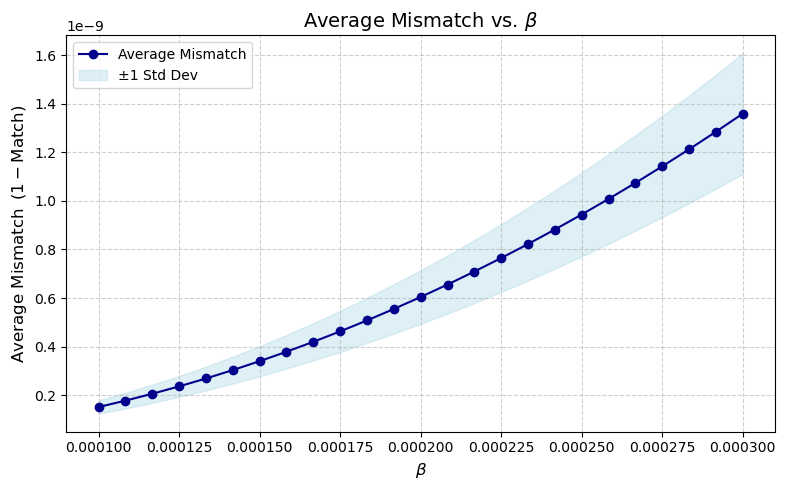

In [432]:
# Define beta values to scan (linearly spaced)
beta_values = np.linspace(0.0001, 0.0003, 25)

# Containers for results
avg_matches = []
std_matches = []

# Loop over beta values and compute average match
for beta in beta_values:
    match_values = []

    for event_id in event_ids:
        h_bgr_full, _ = modify_gr_to_bgr(event_id, beta)

        if h_bgr_full is None or event_id not in hpf:
            continue

        try:
            match_val, _ = match(
                h_bgr_full, hpf[event_id],
                low_frequency_cutoff=10
            )
            match_values.append(match_val)
        except:
            continue

    if len(match_values) > 0:
        avg_matches.append(np.mean(match_values))
        std_matches.append(np.std(match_values))
    else:
        avg_matches.append(np.nan)
        std_matches.append(np.nan)

# Convert to arrays
avg_matches = np.array(avg_matches)
std_matches = np.array(std_matches)
avg_mismatches = 1 - avg_matches

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(beta_values, avg_mismatches, '-o', label='Average Mismatch', color='darkblue')
plt.fill_between(beta_values,
                 avg_mismatches - std_matches,
                 avg_mismatches + std_matches,
                 color='lightblue', alpha=0.4, label='±1 Std Dev')

# Plot settings
plt.xlabel(r'$\beta$', fontsize=12)
plt.ylabel(r'Average Mismatch $\, (1 - \mathrm{Match})$', fontsize=12)
plt.title(r'Average Mismatch vs. $\beta$', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("../figures/avg_mismatch_vs_beta_response.pdf", format='pdf')
plt.show()



In [27]:
# Dictionaries to store paired GR & BGR waveforms
hp_BGR_beta_dict = {}
hp_22_BGR_beta_dict = {}
phase_beta_dict = {}
phase_22_beta_dict = {}

# Generate BGR waveforms for each event using unique IDs
for event_id in event_ids:
    # Generate the BGR waveform
    h_bgr_full, h22_bgr_full = modify_gr_to_bgr(event_id, beta)

    # Ensure waveform generation was successful before storing
    if h_bgr_full is None or h22_bgr_full is None:
        print(f"⚠️ Warning: Skipping event {event_id} due to missing or invalid BGR waveforms.")
        continue  # Skip this event

    # Store the paired GR/BGR waveforms
    hp_BGR_beta_dict[event_id] = h_bgr_full
    hp_22_BGR_beta_dict[event_id] = h22_bgr_full

    # Store phase information for analysis
    phase_beta_dict[event_id] = np.angle(h_bgr_full)
    phase_22_beta_dict[event_id] = np.angle(h22_bgr_full)

print(f"✅ Done generating paired GR/BGR waveforms with fixed beta ({beta}).")
print(f"Total successful GR-BGR pairs: {len(hp_BGR_beta_dict)}")


✅ Done generating paired GR/BGR waveforms with fixed beta (0.0003).
Total successful GR-BGR pairs: 1331


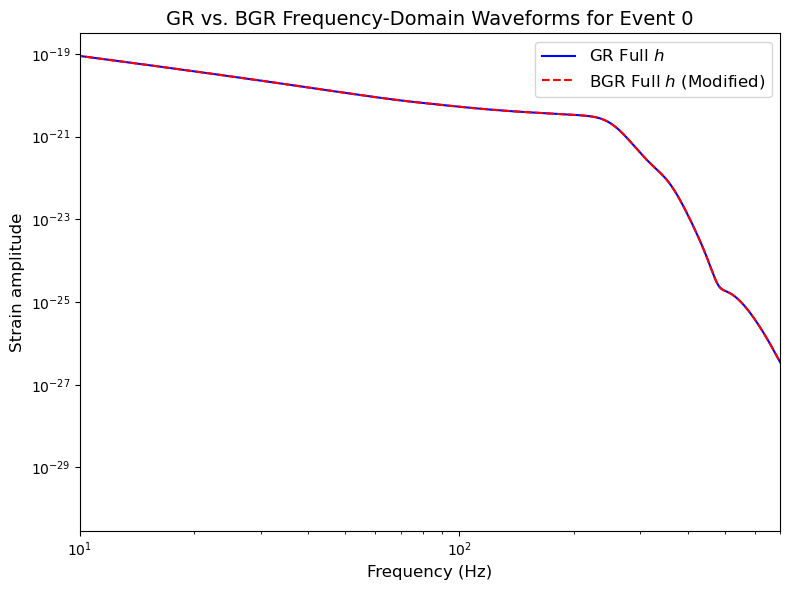

In [29]:
# Choose an event to plot
event_id = event_ids[0]  # Change to any valid event

# Ensure the event exists in required dictionaries
if event_id not in freqs or event_id not in hpf or event_id not in hp_BGR_beta_dict:
    print(f"⚠️ Warning: Event {event_id} missing in GR or BGR waveforms. Cannot plot.")
else:
    try:
        # Extract frequency-domain waveforms for GR and BGR
        f_values = freqs[event_id]  # Frequency array

        # Extract full waveforms (absolute values)
        h_gr = np.abs(hpf[event_id])        # GR Full waveform
        h_bgr = np.abs(hp_BGR_beta_dict[event_id])  # BGR Full waveform

        # Create the plot
        fig, ax = plt.subplots(figsize=(8, 6))

        # Plot GR & BGR waveforms
        ax.plot(f_values, h_gr, color='blue', label="GR Full $h$")
        ax.plot(f_values, h_bgr, color='red', linestyle="--", label="BGR Full $h$ (Modified)")

        # Set labels and log-log scales
        ax.set_xlabel("Frequency (Hz)", fontsize=12)
        ax.set_ylabel("Strain amplitude", fontsize=12)
        ax.set_title(f"GR vs. BGR Frequency-Domain Waveforms for Event {event_id}", fontsize=14)
        ax.set_xscale("log")  # Log scale for frequency
        ax.set_yscale("log")  # Log scale for strain amplitude
        
        # Explicitly set x-axis limits from 10 Hz to 700 Hz
        ax.set_xlim([10, 700])

        ax.legend(fontsize=12)
        plt.tight_layout()
        plt.savefig('Deviation.png')
        plt.show()

    except Exception as e:
        print(f"⚠️ Error: Failed to plot event {event_id}. Error: {e}")



### Noise Injection

In [31]:

def add_colored_noise_to_signal(signal, psd, seed=None, f_max_cutoff=400):
    """Add realistic colored noise to a signal, avoiding high-frequency issues.

    Arguments:
      - signal: The input frequency-domain waveform (PyCBC FrequencySeries).
      - psd: The power spectral density of the detector noise.
      - seed: (Optional) Seed for reproducibility.
      - f_max_cutoff: The maximum frequency where noise is added.
      
    Returns:
      - The noisy signal (PyCBC FrequencySeries), or None if failed.
    """
    if signal is None or psd is None:
        print(f"⚠️ Warning: Skipping noise addition due to missing signal or PSD.")
        return None  # Avoids processing errors

    try:
        # Generate frequency-dependent noise
        noise = pycbc.noise.gaussian.frequency_noise_from_psd(psd, seed=seed)
        noise.resize(len(signal))

        # Convert PyCBC FrequencySeries to NumPy array for manipulation
        noise_np = np.array(noise)
        freq_array = np.array(signal.sample_frequencies)

        # Apply the high-frequency cutoff (set noise to 0 above f_max_cutoff)
        noise_np[np.abs(freq_array) > f_max_cutoff] = 0  

        # Return the noisy signal as a FrequencySeries
        return pycbc.types.FrequencySeries(noise_np + np.array(signal), delta_f=signal.delta_f)

    except Exception as e:
        print(f"⚠️ Error: Failed to add noise to signal. Error: {e}")
        return None


# === Waveform Noise Addition ===

# Model (M) waveforms (clean data)
M_gr = {}      # Full GR waveform (h+)
M_gr_22 = {}   # (2,2) GR waveform

# Model (M) waveforms for Beyond GR (BGR)
M_bgr = {}      # Full BGR waveform
M_bgr_22 = {}   # (2,2) BGR waveform

# Signal (S) waveforms (noisy data)
S_gr = {}      # Noisy GR waveform
S_gr_22 = {}   # Noisy (2,2) GR waveform
S_bgr = {}      # Noisy BGR waveform
S_bgr_22 = {}  # Noisy (2,2) BGR waveform

# Iterate over all events (using unique event IDs)
for event_id in event_ids:
    # Ensure the event has a valid GR waveform
    if event_id not in hpf or event_id not in hpf_22:
        print(f"⚠️ Warning: Skipping event {event_id} due to missing GR waveform.")
        continue  # Skip if GR waveform is missing

    # Get clean GR waveforms
    M_gr[event_id] = hpf[event_id]       # Full GR waveform
    M_gr_22[event_id] = hpf_22[event_id]   # (2,2) GR waveform

    # Add noise to GR waveforms with a unique seed for each event
    seed_gr = 10000 + hash(event_id) % 10000
    S_gr[event_id] = add_colored_noise_to_signal(M_gr[event_id], psd, seed=seed_gr)
    S_gr_22[event_id] = add_colored_noise_to_signal(M_gr_22[event_id], psd, seed=seed_gr)

    # Create BGR waveforms using your modification function
    M_bgr[event_id], M_bgr_22[event_id] = modify_gr_to_bgr(event_id, beta)

    # Ensure BGR waveforms were successfully generated before adding noise
    if M_bgr[event_id] is None or M_bgr_22[event_id] is None:
        print(f"⚠️ Warning: Skipping noise addition for event {event_id} due to missing BGR waveform.")
        continue  # Skip if BGR waveform is missing

    # Add noise to BGR waveforms with a different unique seed
    seed_bgr = 20000 + hash(event_id) % 10000
    S_bgr[event_id] = add_colored_noise_to_signal(M_bgr[event_id], psd, seed=seed_bgr)
    S_bgr_22[event_id] = add_colored_noise_to_signal(M_bgr_22[event_id], psd, seed=seed_bgr)

print("✅ Done adding noise to GR and BGR waveforms.")


✅ Done adding noise to GR and BGR waveforms.


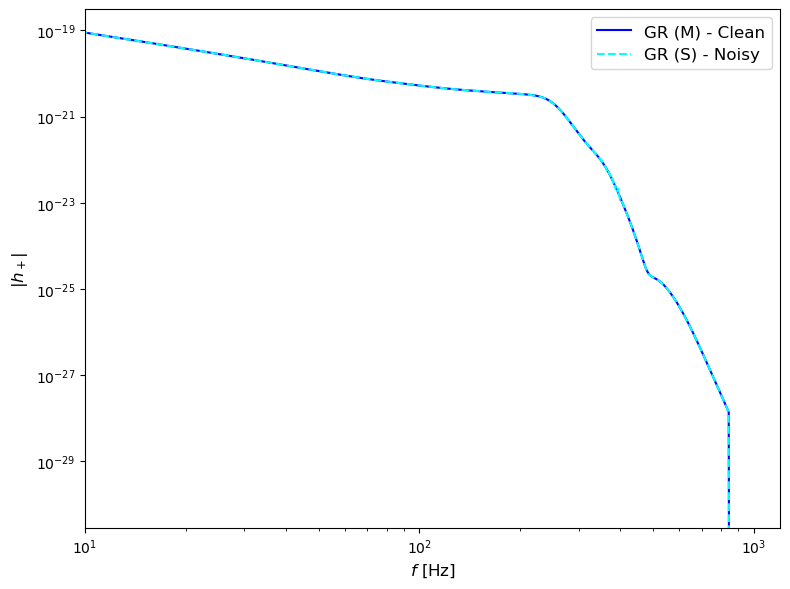

In [390]:
# Choose an event to plot (use a unique event ID)
event_id = event_ids[0]  # Change this to any event from your dataset

# Ensure the event exists in the required dictionaries
if event_id not in freqs or event_id not in M_gr or event_id not in S_gr:
    print(f"⚠️ Warning: Event {event_id} is missing from one of the waveform dictionaries.")
else:
    # Extract frequency domain waveform information
    f_values = freqs[event_id]  # Frequency array

    # GR (M): Clean GR waveform (model waveform)
    M_gr_waveform = np.abs(M_gr[event_id])
    
    # GR (S): Noisy GR waveform (signal with noise added)
    S_gr_waveform = np.abs(S_gr[event_id])
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(f_values, M_gr_waveform, color='blue', label='GR (M) - Clean')
    ax.plot(f_values, S_gr_waveform, color='cyan', linestyle='dashed', label='GR (S) - Noisy')
    
    # Format the plot: log-log scales and axis labels
    ax.set_xlabel('$f$ [Hz]', fontsize=12)
    ax.set_ylabel('$|h_+|$', fontsize=12)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim([10, 1200])  # Adjust frequency range as needed
    ax.legend(fontsize=12)
    
    plt.tight_layout()
    plt.show()


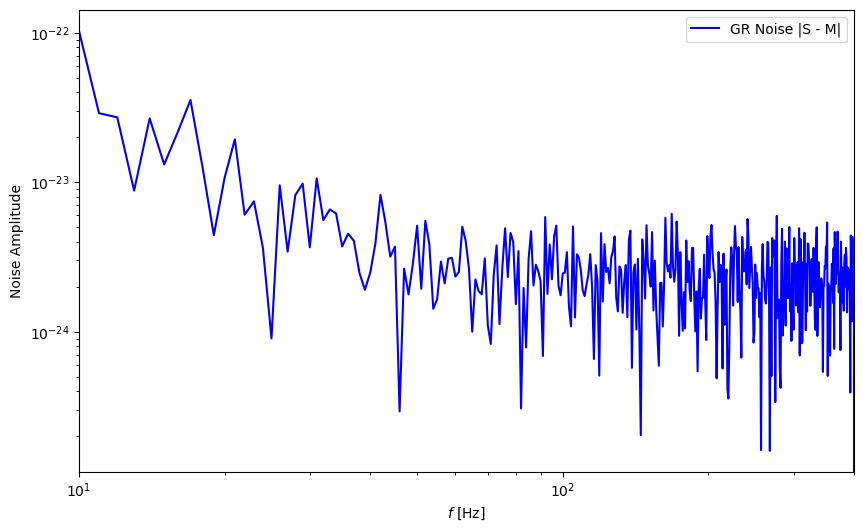

In [336]:
# Choose an event to plot
event_id = event_ids[0]  # Change to any event from your dataset

# Extract frequency domain waveforms
f_values = freqs[event_id]  # Frequency array

# Compute the noise by subtracting clean GR waveform from noisy GR waveform
GR_noise = np.abs(S_gr[event_id] - M_gr[event_id])  

# Plot the noise amplitude
fig, ax = plt.subplots()

ax.plot(f_values, GR_noise, color='blue', label='GR Noise |S - M|')

# Formatting the plot
ax.set_xlabel('$f$ [Hz]')
ax.set_ylabel('Noise Amplitude')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim([10, 400])  # Adjust frequency range
ax.legend()

plt.show()


In [32]:
# Initialize dictionaries for storing results
match_GR = {}        # Match values for GR waveforms
match_bgr = {}       # Match values for BGR waveforms
response = {}        # Response functions for GR
response_bgr = {}    # Response functions for BGR

# Dictionaries for normalization factors and normalized (and conjugated) waveforms
norm_M_gr = {}
norm_S_gr = {}
norm_M_bgr = {}
norm_S_bgr = {}

M_gr_normalized = {}
S_gr_normalized = {}
M_bgr_normalized = {}
S_bgr_normalized = {}

M_gr_conjugate_normalized = {}
S_gr_conjugate_normalized = {}
S_bgr_conjugate_normalized = {}

for event_id in event_ids:
    # Retrieve the frequency array and the corresponding indices for the current event.
    freq_array = freqs[event_id]
    index_lo = id_lo[event_id]
    index_hi = id_hi[event_id] + 1  # Include the last valid index

    # Determine the length of the valid frequency region
    resp_len = len(freq_array[index_lo:index_hi])
    
    # Slice the PSD to match the event's frequency region
    psd_slice = psd[index_lo:index_lo + resp_len]
    
    # Slice GR waveforms over the valid frequency region
    M_gr_slice = M_gr[event_id][index_lo:index_lo + resp_len]
    S_gr_slice = S_gr[event_id][index_lo:index_lo + resp_len]
    M_gr_22_slice = M_gr_22[event_id][index_lo:index_lo + resp_len]
    
    # Slice BGR waveforms over the valid frequency region
    M_bgr_slice = M_bgr[event_id][index_lo:index_lo + resp_len]
    S_bgr_slice = S_bgr[event_id][index_lo:index_lo + resp_len]
    
    # Calculate normalization factors using the weighted inner product (PyCBC's method)
    norm_M_gr[event_id] = np.sqrt(M_gr_slice.weighted_inner(M_gr_slice, psd_slice))
    norm_S_gr[event_id] = np.sqrt(S_gr_slice.weighted_inner(S_gr_slice, psd_slice))
    norm_M_bgr[event_id] = np.sqrt(M_bgr_slice.weighted_inner(M_bgr_slice, psd_slice))
    norm_S_bgr[event_id] = np.sqrt(S_bgr_slice.weighted_inner(S_bgr_slice, psd_slice))
    
    # Normalize the waveforms
    M_gr_normalized[event_id] = M_gr_slice / norm_M_gr[event_id]
    S_gr_normalized[event_id] = S_gr_slice / norm_S_gr[event_id]
    M_bgr_normalized[event_id] = M_bgr_slice / norm_M_bgr[event_id]
    S_bgr_normalized[event_id] = S_bgr_slice / norm_S_bgr[event_id]
    
    # Compute the complex conjugates of the normalized waveforms
    M_gr_conjugate_normalized[event_id] = M_gr_normalized[event_id].conj()
    S_gr_conjugate_normalized[event_id] = S_gr_normalized[event_id].conj()
    S_bgr_conjugate_normalized[event_id] = S_bgr_normalized[event_id].conj()
    
    # Calculate match values between the model and signal waveforms for GR and BGR
    match_GR_value, _ = matchedfilter.optimized_match(M_gr_slice, S_gr_slice, psd=psd_slice)
    match_GR[event_id] = match_GR_value
    
    match_bgr_value, _ = matchedfilter.optimized_match(M_gr_slice, S_bgr_slice, psd=psd_slice)
    match_bgr[event_id] = match_bgr_value
    
    # Calculate the response function for GR:
    # The response function here is defined as:
    #   response = (4 i M_gr_22_slice / (norm_M_gr * psd_slice)) * 
    #              (- S_gr_normalized_conjugate + match_GR * M_gr_normalized_conjugate)
    response[event_id] = (4 * 1j * M_gr_22_slice / (norm_M_gr[event_id] * psd_slice)) * \
                         (-S_gr_conjugate_normalized[event_id] + match_GR[event_id] * M_gr_conjugate_normalized[event_id])
    
    # Calculate the response function for BGR similarly:
    response_bgr[event_id] = (4 * 1j * M_gr_22_slice / (norm_M_gr[event_id] * psd_slice)) * \
                             (-S_bgr_conjugate_normalized[event_id] + match_bgr[event_id] * M_gr_conjugate_normalized[event_id])

# End of response function calculations
print("✅ Response function calculations completed.")



✅ Response function calculations completed.


freq_array shape: (2592,)
response_gr_real shape: (2592,)
response_bgr_real shape: (2592,)


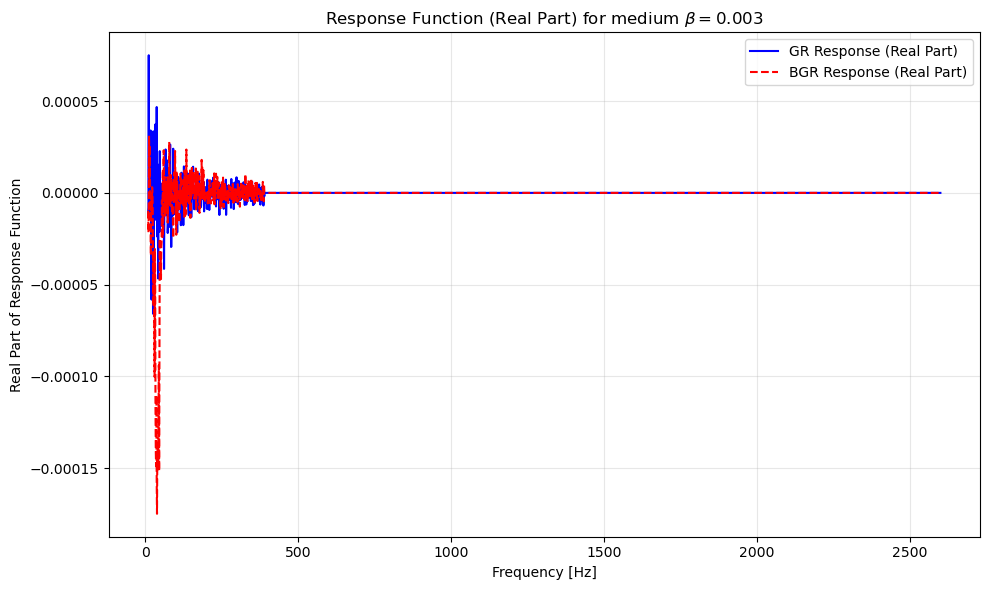

In [472]:
# Choose an event to plot
event_id = event_ids[1]  # Change to any event from your dataset

# Ensure `freq_array` is aligned with the response function's length
resp_len = len(response[event_id][id_lo[event_id]:id_hi[event_id] + 1])

# Retrieve the frequency array (adjusted for length)
freq_array = np.array(freqs[event_id][id_lo[event_id]:id_lo[event_id] + resp_len])

# Retrieve and slice the response functions **before** taking .real()
response_gr_real = response[event_id][id_lo[event_id]:id_lo[event_id] + resp_len].real()
response_bgr_real = response_bgr[event_id][id_lo[event_id]:id_lo[event_id] + resp_len].real()

# Debugging: Print shapes before plotting
print(f"freq_array shape: {freq_array.shape}")
print(f"response_gr_real shape: {response_gr_real.shape}")
print(f"response_bgr_real shape: {response_bgr_real.shape}")

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(freq_array, response_gr_real, label='GR Response (Real Part)', color='blue', linestyle='-')
plt.plot(freq_array, response_bgr_real, label='BGR Response (Real Part)', color='red', linestyle='--')

# Add labels and legend
plt.xlabel('Frequency [Hz]')
plt.ylabel('Real Part of Response Function')
plt.title(r"Response Function (Real Part) for medium $\beta=0.003$")
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/response_comparison_medium.pdf", format='pdf')
# Show the plot
plt.show()



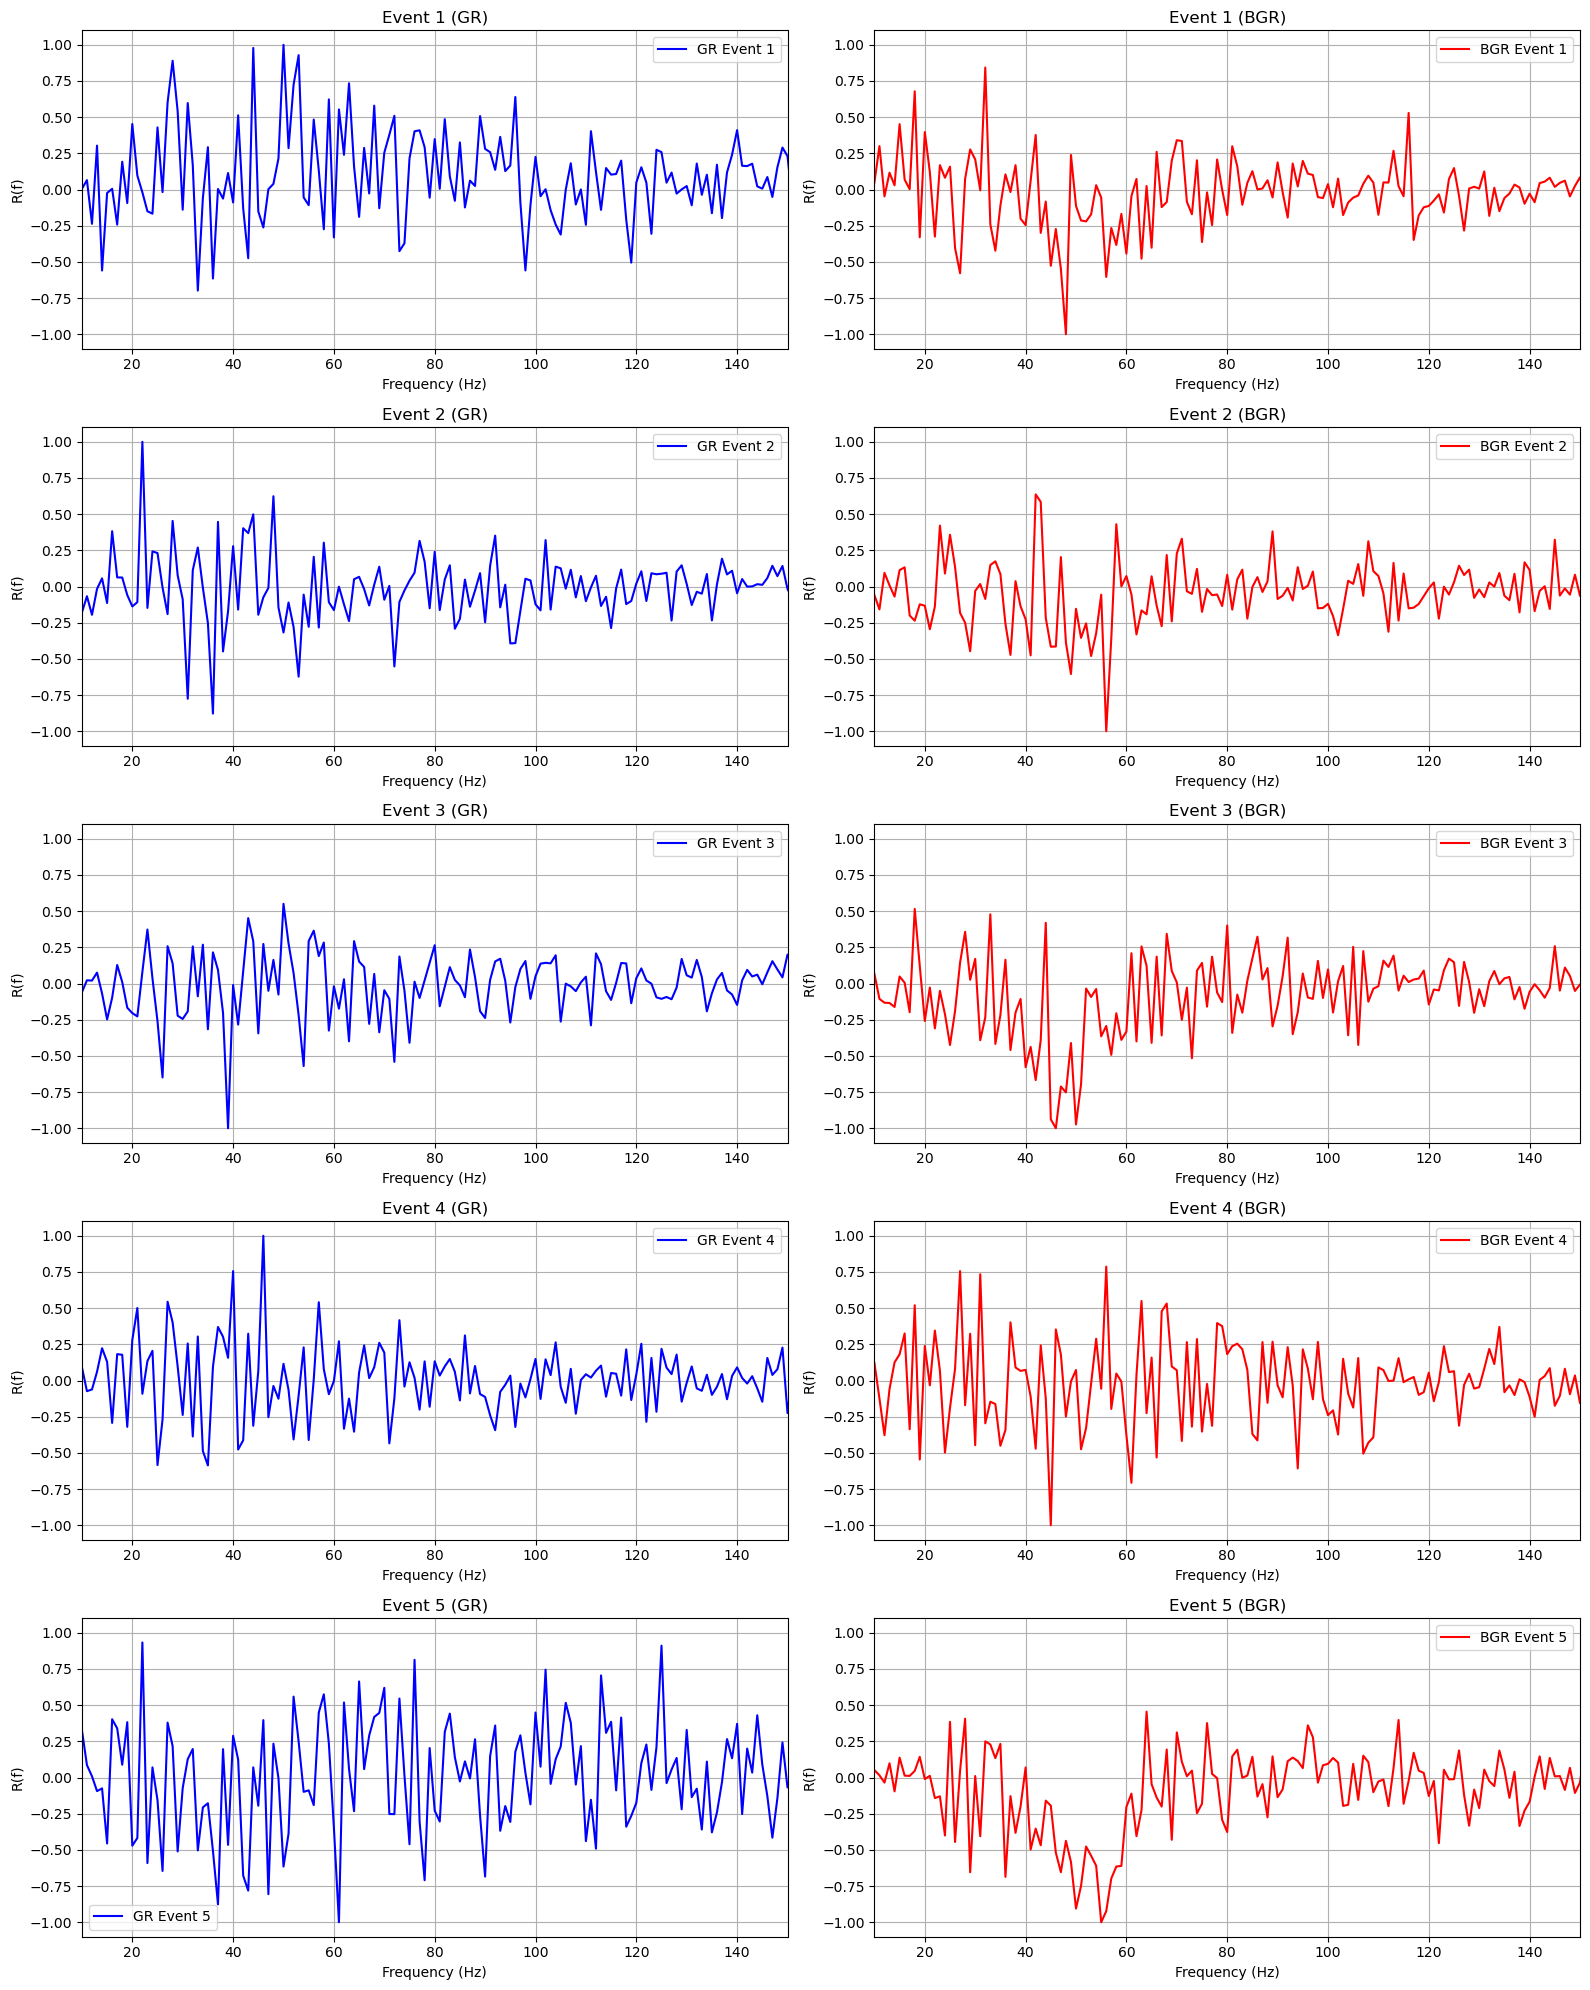

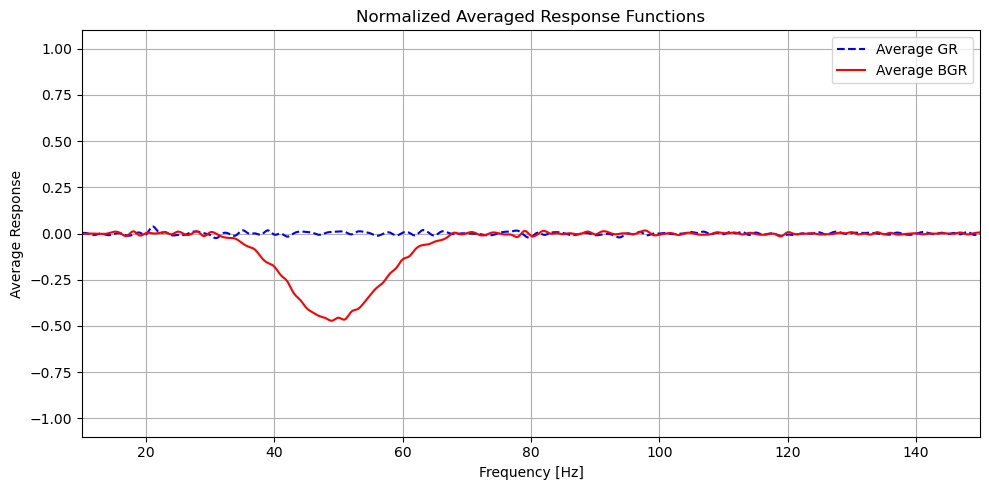

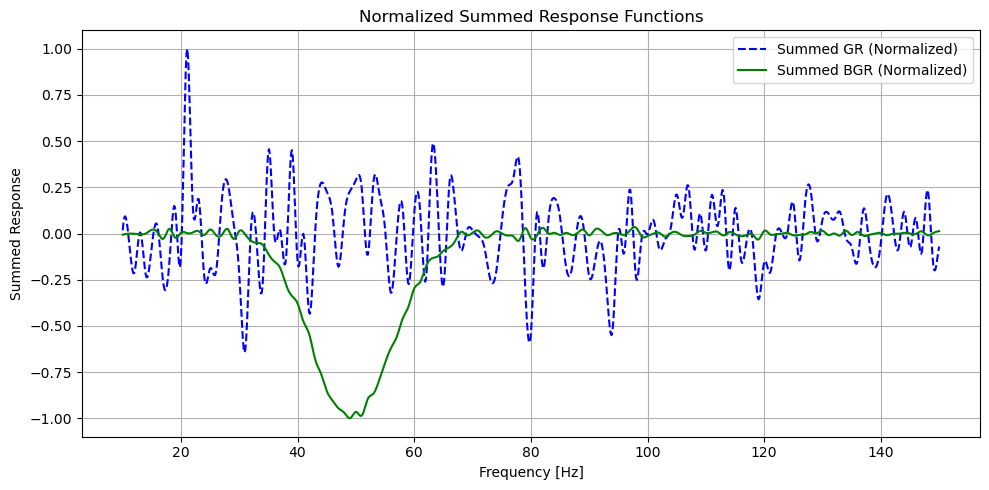

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import random

# Choose 10 events to display
display_ids = list(range(1, 6))


# Define common frequency grid for interpolation and averaging
common_freqs = np.linspace(10, 150, 1000)

# Containers for interpolated responses
interpolated_gr_all = []
interpolated_bgr_all = []

# Interpolate and normalize each response before storing
for i in event_ids:
    freqs_i = freqs[i][id_lo[i]:id_hi[i]+1]
    resp_gr_real = response[i].real().numpy()
    resp_bgr_real = response_bgr[i].real().numpy()

    # Normalize responses
    norm_gr = resp_gr_real / np.max(np.abs(resp_gr_real))
    norm_bgr = resp_bgr_real / np.max(np.abs(resp_bgr_real))

    interp_gr = interp1d(freqs_i, norm_gr, kind='cubic', bounds_error=False, fill_value=0.0)
    interp_bgr = interp1d(freqs_i, norm_bgr, kind='cubic', bounds_error=False, fill_value=0.0)

    interpolated_gr_all.append(interp_gr(common_freqs))
    interpolated_bgr_all.append(interp_bgr(common_freqs))

# Compute average and sum, and normalize sums to [-1, 1]
avg_response_gr = np.mean(interpolated_gr_all, axis=0)
avg_response_bgr = np.mean(interpolated_bgr_all, axis=0)
sum_response_gr = np.sum(interpolated_gr_all, axis=0)
sum_response_bgr = np.sum(interpolated_bgr_all, axis=0)

sum_response_gr /= np.max(np.abs(sum_response_gr))
sum_response_bgr /= np.max(np.abs(sum_response_bgr))

# === Plotting individual GR/BGR events ===
subplot_height = 4
subplot_width = 8
fig, axs = plt.subplots(len(display_ids), 2, figsize=(subplot_width * 2, subplot_height * len(display_ids)))

def plot_data(ax, freqs, response_array, label, title, xlims, color='blue'):
    response_real = response_array.real().numpy()
    norm_response = response_real / np.max(np.abs(response_real))
    ax.plot(freqs, norm_response, label=label, color=color)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('R(f)')
    ax.set_title(title)
    ax.grid(True)
    ax.set_xlim(xlims)
    ax.set_ylim([-1.1, 1.1])
    ax.legend()

for j, i in enumerate(display_ids):
    freq_range = freqs[i][id_lo[i]:id_hi[i]+1]
    plot_data(axs[j, 0], freq_range, response[i], f'GR Event {j+1}', f'Event {j+1} (GR)', (10, 150), color='blue')
    plot_data(axs[j, 1], freq_range, response_bgr[i], f'BGR Event {j+1}', f'Event {j+1} (BGR)', (10, 150), color='red')

plt.tight_layout()
plt.savefig("../figures/response_comparison_noisy.pdf", format='pdf')
plt.show()

# === Plot: Normalized Averaged Responses ===
plt.figure(figsize=(10, 5))
plt.plot(common_freqs, avg_response_gr, label='Average GR', color='blue', linestyle='--')
plt.plot(common_freqs, avg_response_bgr, label='Average BGR', color='red', linestyle='-')
plt.title('Normalized Averaged Response Functions')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Average Response')
plt.ylim([-1.1, 1.1])
plt.xlim([10, 150])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/response_avg.pdf", format='pdf')
plt.show()

# === Plot: Normalized Summed Responses ===
plt.figure(figsize=(10, 5))
plt.plot(common_freqs, sum_response_gr, label='Summed GR (Normalized)', color='blue', linestyle='--')
plt.plot(common_freqs, sum_response_bgr, label='Summed BGR (Normalized)', color='green', linestyle='-')
plt.title('Normalized Summed Response Functions')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Summed Response')
plt.ylim([-1.1, 1.1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



## ML Implementation

In [339]:
import numpy as np
from scipy.interpolate import interp1d
from sklearn.model_selection import train_test_split

# Define frequency bounds and common grid
f_min = 10
f_max = 400
N_points = 1000  # Adjust as needed
f_common = np.linspace(f_min, f_max, N_points)

def process_response_real(fs, f_common):
    """
    Process a (complex) PyCBC FrequencySeries response function by extracting only its real part.
    The resulting real data is interpolated onto a common frequency grid.
    
    Arguments:
      fs       : PyCBC FrequencySeries object representing the response function.
      f_common : 1D numpy array defining the common frequency grid.
    
    Returns:
      A 1D numpy array of the real part of the response function on the f_common grid.
    """
    # Get the original frequency and complex data arrays from the FrequencySeries.
    freqs = fs.sample_frequencies.numpy()
    # Extract only the real part
    data_real = fs.numpy().real
    
    # Limit data to the frequency range [f_min, f_max]
    mask = (freqs >= f_min) & (freqs <= f_max)
    freqs = freqs[mask]
    data_real = data_real[mask]
    
    # Create an interpolation function; fill values outside the range with 0
    interp_func = interp1d(freqs, data_real, kind='linear', bounds_error=False, fill_value=0)
    return interp_func(f_common)

# Process the response functions for both GR and BGR
X_resp_gr = []
X_resp_bgr = []

# Here, response and response_bgr are assumed to be dictionaries keyed by event IDs
for event_id in event_ids:
    X_resp_gr.append(process_response_real(response[event_id], f_common))
    X_resp_bgr.append(process_response_real(response_bgr[event_id], f_common))

# Convert lists to NumPy arrays; each sample now has shape (N_points,)
X_resp_gr = np.array(X_resp_gr)
X_resp_bgr = np.array(X_resp_bgr)

# Create labels: 0 for GR, 1 for BGR
y_resp_gr = np.zeros(len(X_resp_gr))
y_resp_bgr = np.ones(len(X_resp_bgr))

# Concatenate GR and BGR data and their labels
X = np.concatenate([X_resp_gr, X_resp_bgr], axis=0)
y = np.concatenate([y_resp_gr, y_resp_bgr], axis=0)

# Shuffle the dataset
indices = np.arange(len(X))
np.random.shuffle(indices)
X = X[indices]
y = y[indices]

# Split the dataset: 70% train, 15% validation, 15% test (with stratification)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print(f"Train shape: {X_train.shape}, Val shape: {X_val.shape}, Test shape: {X_test.shape}")

# --- Per-Sample Normalization (Z-score normalization) ---
# Normalize each sample individually
X_train = (X_train - np.mean(X_train, axis=1, keepdims=True)) / np.std(X_train, axis=1, keepdims=True)
X_val   = (X_val   - np.mean(X_val, axis=1, keepdims=True))   / np.std(X_val, axis=1, keepdims=True)
X_test  = (X_test  - np.mean(X_test, axis=1, keepdims=True))  / np.std(X_test, axis=1, keepdims=True)

# Now, X_train, X_val, and X_test are ready to be fed into your neural network.


Train shape: (1863, 1000), Val shape: (399, 1000), Test shape: (400, 1000)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_39 (Conv1D)              │ (None, 998, 16)        │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_39 (MaxPooling1D) │ (None, 499, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_40 (Conv1D)              │ (None, 497, 32)        │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_40 (MaxPooling1D) │ (None, 248, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_41 (Conv1D)              │ (None, 246, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_41 (MaxPooling1D) │ (None, 123, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 7872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │     1,007,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,015,713 (3.87 MB)

 Trainable params: 1,015,713 (3.87 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 103ms/step - accuracy: 0.6617 - loss: 0.4220 - val_accuracy: 1.0000 - val_loss: 0.1034
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 1.0000 - loss: 0.0811 - val_accuracy: 1.0000 - val_loss: 0.0434
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 1.0000 - loss: 0.0407 - val_accuracy: 1.0000 - val_loss: 0.0329
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 1.0000 - loss: 0.0324 - val_accuracy: 1.0000 - val_loss: 0.0289
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 1.0000 - loss: 0.0288 - val_accuracy: 1.0000 - val_loss: 0.0266
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 1.0000 - loss: 0.0265 - val_accuracy: 1.0000 - val_loss: 0.0249
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 1.0000 - loss: 0.0248 - val_accuracy: 1.0000 - val_loss: 0.0236
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 104ms/step - accuracy: 1.0000 - loss: 0.0235 - val_accuracy: 1.0000 -

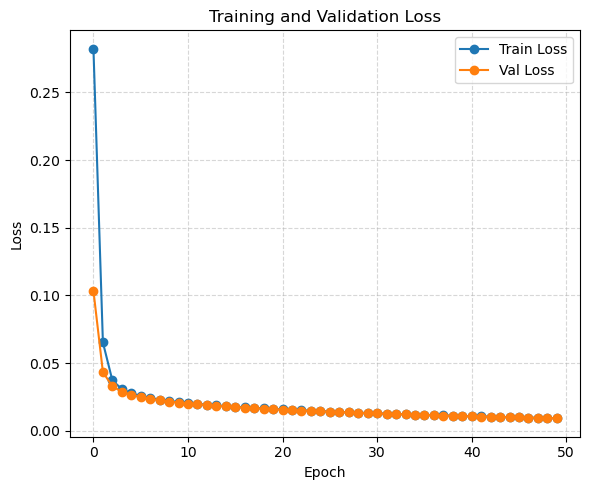

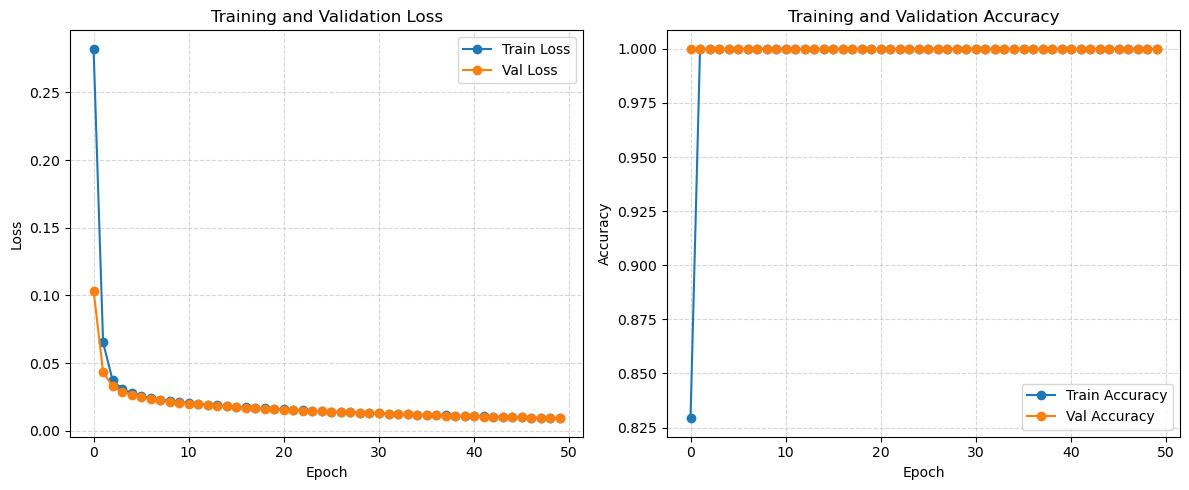

In [340]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Set seed for reproducibility
tf.random.set_seed(42)

def create_cnn(input_shape, learning_rate=1e-3, l2_reg=1e-2):
    """
    Build a 1D CNN model for classifying GR vs. BGR waveforms.
    The output layer is linear (logits) and will be passed through a sigmoid via
    the loss function (using from_logits=True).
    L2 regularization is applied to help prevent overfitting.
    """
    # Ensure the input shape includes a channel dimension.
    # If input_shape is (num_features,), change it to (num_features, 1)
    if len(input_shape) == 1:
        input_shape = (input_shape[0], 1)
    
    model = models.Sequential([
        layers.Input(shape=input_shape),
        # Convolutional Block 1:
        layers.Conv1D(16, kernel_size=3, activation='relu',
                      kernel_regularizer=regularizers.l2(l2_reg)),
        layers.MaxPooling1D(pool_size=2),
        
        # Convolutional Block 2:
        layers.Conv1D(32, kernel_size=3, activation='relu',
                      kernel_regularizer=regularizers.l2(l2_reg)),
        layers.MaxPooling1D(pool_size=2),
        
        # Optional additional convolutional layer for deeper features:
        layers.Conv1D(64, kernel_size=3, activation='relu',
                      kernel_regularizer=regularizers.l2(l2_reg)),
        layers.MaxPooling1D(pool_size=2),
        
        
        # Flatten and Dense layers:
        layers.Flatten(),
        layers.Dense(128, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dense(1, activation='linear')  # Output layer producing logits
    ])
    
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer,
                  loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
                  metrics=['accuracy'])
    return model

# Get input shape from training data (assumed preprocessed in Block 1)
# For example, if X_train originally has shape (num_samples, 400)
input_shape = X_train.shape[1:]  # e.g., (400,)
model = create_cnn(input_shape, learning_rate=1e-4, l2_reg=1e-4)
model.summary()

# Train the model (without early stopping)
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=50, batch_size=64, verbose=1)

# Plot the training history: Loss and Accuracy curves




# Plot both subplots for notebook display
plt.figure(figsize=(12,5))

# --- Loss subplot (this one will also be saved) ---
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Save just the loss subplot separately
# Re-create the left plot alone in a separate figure
plt.figure(figsize=(6,5))
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("../figures/training_loss_beta1.pdf", format='pdf')

# --- Accuracy subplot (for notebook only) ---
plt.figure(1)  # go back to the first figure
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Final display of the 2-panel plot
plt.tight_layout()
plt.show()


Test Loss: 0.0093, Test Accuracy: 1.0000
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


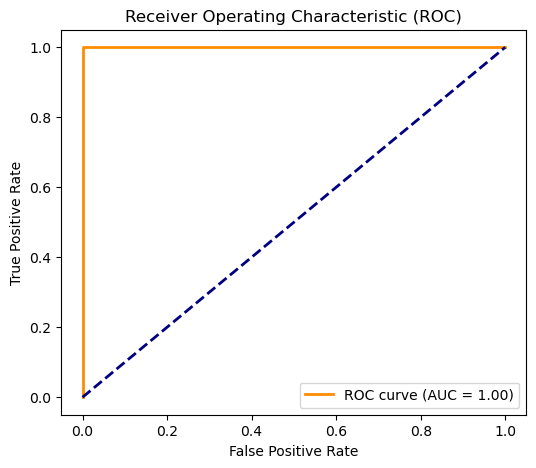

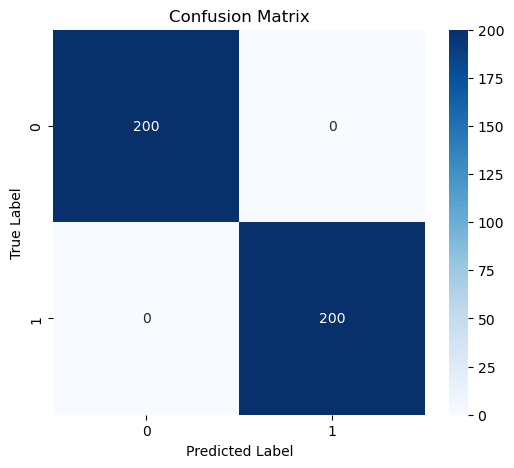

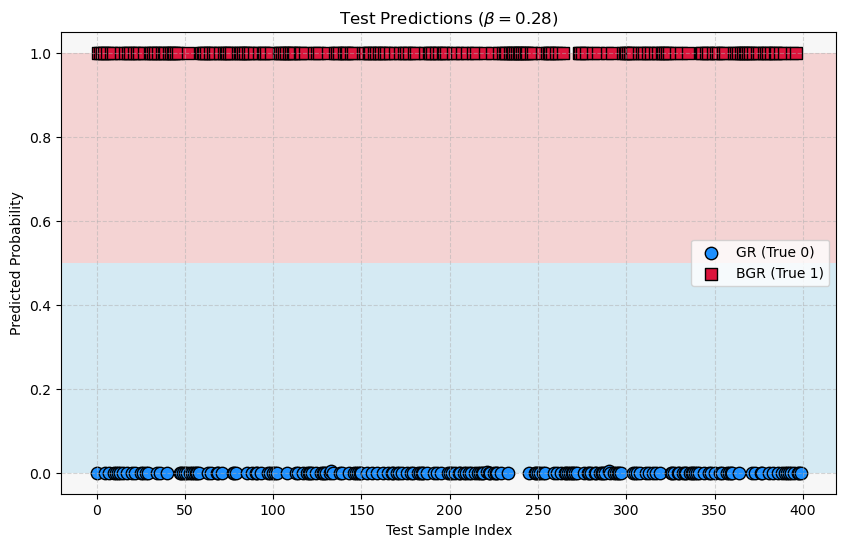

In [341]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Evaluate on the test set
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# Obtain model predictions (logits) and convert to probabilities
y_logits = model.predict(X_test)
y_pred_prob = tf.sigmoid(y_logits).numpy().ravel()
y_pred_class = (y_pred_prob > 0.5).astype(int)

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.savefig("../figures/confusion1.pdf", format='pdf')
plt.show()

# --- Colorful Scatter Plot with Background ---
plt.figure(figsize=(10,6))
ax = plt.gca()

# Set a light background color for the plot
ax.set_facecolor('#f7f7f7')

# Fill horizontal background regions:
# Region for probabilities from 0 to 0.5 (e.g., associated with GR)
ax.axhspan(0, 0.5, facecolor='skyblue', alpha=0.3)
# Region for probabilities from 0.5 to 1 (e.g., associated with BGR)
ax.axhspan(0.5, 1, facecolor='lightcoral', alpha=0.3)

# Get indices for each true class in the test set
indices0 = np.where(y_test == 0)[0]
indices1 = np.where(y_test == 1)[0]

# Plot test predictions with different markers and colors based on true labels
plt.scatter(indices0, y_pred_prob[indices0], s=80, c='dodgerblue',
            label='GR (True 0)', edgecolor='k', marker='o')
plt.scatter(indices1, y_pred_prob[indices1], s=80, c='crimson',
            label='BGR (True 1)', edgecolor='k', marker='s')

plt.xlabel("Test Sample Index")
plt.ylabel("Predicted Probability")
plt.title(r"Test Predictions ($\beta=0.28$)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("../figures/Probablity1.pdf", format='pdf')
plt.show()


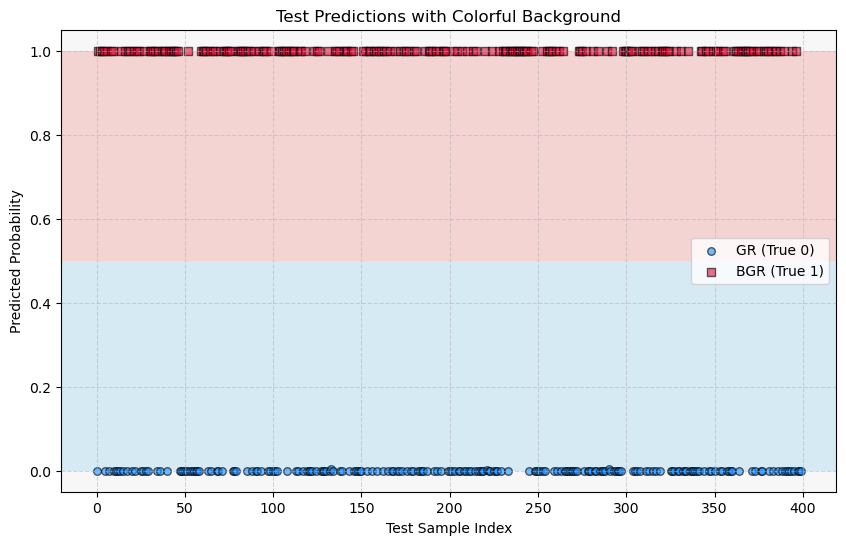

In [342]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
ax = plt.gca()
ax.set_facecolor('#f7f7f7')

# Fill background regions
ax.axhspan(0, 0.5, facecolor='skyblue', alpha=0.3)
ax.axhspan(0.5, 1, facecolor='lightcoral', alpha=0.3)

# Get indices for each class
indices0 = np.where(y_test == 0)[0]
indices1 = np.where(y_test == 1)[0]

# Plot predictions with reduced marker size and increased transparency
plt.scatter(indices0, y_pred_prob[indices0], s=30, c='dodgerblue',
            label='GR (True 0)', edgecolor='k', marker='o', alpha=0.6)
plt.scatter(indices1, y_pred_prob[indices1], s=30, c='crimson',
            label='BGR (True 1)', edgecolor='k', marker='s', alpha=0.6)

plt.xlabel("Test Sample Index")
plt.ylabel("Predicted Probability")
plt.title("Test Predictions with Colorful Background")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [343]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

# Compute predicted classes using a 0.5 threshold on the predicted probabilities
y_pred_class = (y_pred_prob > 0.5).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred_class)
precision = precision_score(y_test, y_pred_class)
recall = recall_score(y_test, y_pred_class)
f1 = f1_score(y_test, y_pred_class)

# Print results
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000


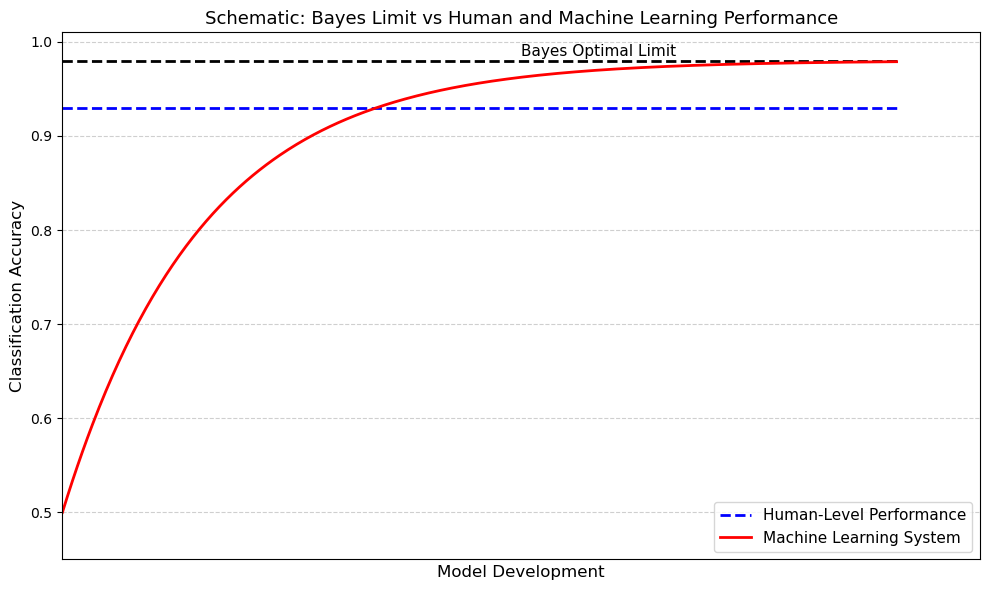

In [363]:

import matplotlib.pyplot as plt
import numpy as np

# Dummy x-axis for schematic progression
x = np.linspace(0, 10, 500)

# Performance curves
bayes_limit = np.ones_like(x) * 0.98
human_performance = np.ones_like(x) * 0.93
machine_performance = 0.5 + 0.48 * (1 - np.exp(-0.6 * x))  # Asymptotes to ~0.98

# Plot setup
plt.figure(figsize=(10, 6))
plt.plot(x, bayes_limit, 'k--', linewidth=2)
plt.plot(x, human_performance, 'b--', label="Human-Level Performance", linewidth=2)
plt.plot(x, machine_performance, 'r-', label="Machine Learning System", linewidth=2)

# Label Bayes limit without arrow
plt.text(5.5, 0.985, "Bayes Optimal Limit", fontsize=11)

# Labels and title
plt.xlabel("Model Development", fontsize=12)
plt.ylabel("Classification Accuracy", fontsize=12)
plt.title("Schematic: Bayes Limit vs Human and Machine Learning Performance", fontsize=13)

# Cosmetic adjustments
plt.xticks([])  # Remove x-axis numbers
plt.ylim(0.45, 1.01)
plt.xlim(0, 11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig("../figures/Bayes.pdf", format='pdf')
plt.show()

